# 3. Baseline: TF-IDF + Logistic Regression (3i)
**Owner:** Maggie | **Rubric:** Baseline Model (10%)

TF-IDF is allowed **only** here and in the baseline tuning. Evaluate with Accuracy, Precision, Recall and F1 via `evaluate()`. Tune with `get_cv()` on train only; touch the test set once. Variable prefix: `bl_`.

In [10]:
# Standard setup - do not edit. Tagged 'setup'; scripts/merge_notebooks.py replaces it in the final notebook.
import os, sys
sys.path.insert(0, os.path.abspath('../..' if os.path.basename(os.getcwd()) == 'models' else '..'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.common import *
set_seed()

## 3.1 Load processed data (use `text_tfidf`)

In [11]:
bl_train, bl_test = load_processed()
bl_X_train, bl_y_train = bl_train['StemmedText'], bl_train['Sentiment']
bl_X_test, bl_y_test = bl_test['StemmedText'], bl_test['Sentiment']
#bl_X_train, bl_y_train = bl_train['text_tfidf'], bl_train['Sentiment']
#bl_X_test, bl_y_test = bl_test['text_tfidf'], bl_test['Sentiment']

## 3.2 Pipeline and 5-fold CV on train
`Pipeline([('tfidf', TfidfVectorizer()), ('lr', LogisticRegression(max_iter=1000, random_state=SEED))])`, scored with `cross_val_score(..., cv=get_cv(), scoring='f1_macro')`. Report mean ± std.

In [29]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.metrics import ConfusionMatrixDisplay
bl_pipe = Pipeline([('tfidf', TfidfVectorizer()), ('lr', LogisticRegression(max_iter=1000, random_state=SEED))])
score = cross_val_score(bl_pipe, bl_X_train, bl_y_train, cv=get_cv(), scoring='f1_macro')

## 3.3 Fit on full train, evaluate on test (benchmark)

In [30]:
bl_pipe.fit(bl_X_train, bl_y_train)
bl_res = evaluate(bl_y_test, bl_pipe.predict(bl_X_test), 'baseline_tfidf-lr', meta={
    'owner': 'maggie', 'description': 'TF-IDF (default params) + Logistic Regression, untuned benchmark',
    'params': {}, 'cv_f1_macro_mean': None, 'cv_f1_macro_std': None})

                   precision    recall  f1-score   support

         negative      0.000     0.000     0.000        42
somewhat negative      0.338     0.506     0.405        89
          neutral      0.176     0.045     0.071        67
somewhat positive      0.317     0.620     0.419        92
         positive      0.700     0.137     0.230        51

         accuracy                          0.328       341
        macro avg      0.306     0.261     0.225       341
     weighted avg      0.313     0.328     0.267       341

macro-F1 0.225 | accuracy 0.328 | QWK 0.248 | MAE 1.056


## 3.4 Per-class results and confusion matrix
`save_fig(fig, 'baseline_01_confusion_matrix')`, with a takeaway on which classes get confused.

WindowsPath('C:/Users/hola5/dsai4205-team20-movie-sentiment/figures/baseline_01_confusion_matrix.png')

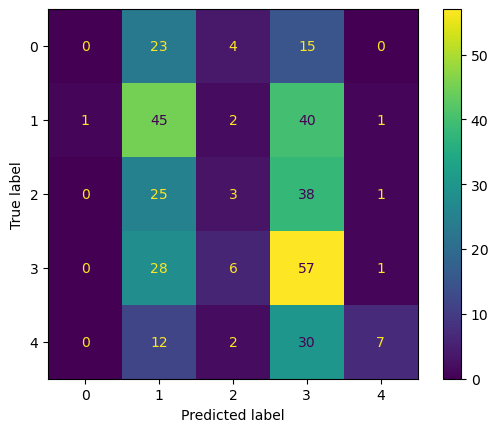

In [32]:
disp = ConfusionMatrixDisplay.from_estimator(bl_pipe, bl_X_test, bl_y_test)
#Create a confusion matrix display from the trained pipeline

save_fig(disp.figure_, 'baseline_01_confusion_matrix')

## 3.5 Tuned baseline (feeds 3iv)
Grid over C, ngram_range, min_df and class_weight with `get_cv()`. Save the table to `results/tuning_improved_baseline_tfidf-lr-tuned.csv`, then evaluate as `improved_baseline_tfidf-lr-tuned`.

## 3.6 Benchmark discussion
_Where the baseline fails (negation, word order, adjacent classes) and what the advanced models should fix._